### Alzheimer's Progression Prediction model 
##### via MRI image dataset from OASIS Alzheimer's dataset
---
Rudy Gamboa | Alex Hernandez | Jeff Ock

In [206]:
## Import modules
# for Data
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
# from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
# for Model
import tensorflow as tf
from tensorflow import keras
import tensorflow.keras                             # type: ignore
from tensorflow.keras.layers import Dense,Dropout   # type: ignore
from tensorflow.keras.applications import MobileNet # type: ignore
from tensorflow.keras.models import Model           # type: ignore
from tensorflow.keras.optimizers import Adam        # type: ignore
# for Other
import os
import cv2
from tqdm import tqdm
import io
import seaborn as sns

---
##### Get Data:
---

In [230]:
# Specify the path to the main data folder
cwd = os.getcwd()
train_path = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "train")
test_path = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "test")

train_datagen = ImageDataGenerator(
    validation_split=0.2  # 20% validation split
)

# Create train_generator iterator object
train_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='training',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Create train_generator iterator object
val_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='validation',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Test data generator
test_datagen = ImageDataGenerator(rescale=1./255)  # Only rescaling, no augmentation

# Test generator
test_generator = test_datagen.flow_from_directory(
    test_path, 
    target_size=(256, 256),
    color_mode='rgb',
    batch_size=16,
    seed=1,
    class_mode='categorical',
    shuffle=False  # Do not shuffle to keep predictions in order
)


Found 538 images belonging to 5 classes.
Found 134 images belonging to 5 classes.
Found 672 images belonging to 5 classes.


In [231]:
labels = ['Reduced AD','Reduced CN', 'Reduced EMCI', 'Reduced LMCI','Reduced MCI']
#labels = ['Final AD JPEG','Final CN JPEG', 'Final EMCI JPEG', 'Final LMCI JPEG','Final MCI JPEG']

X_train = []  # Training Dataset
Y_train = []  # Training Labels
image_size = 150

cwd = os.getcwd()  # Current working directory

for i in labels:
    folderPath = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "train", i)
    for j in tqdm(os.listdir(folderPath)):
        image_path = os.path.join(folderPath, j)
        image = cv2.imread(image_path)
        if image is None:
            print(f"Warning: Unable to load image at {image_path}")
            continue
        image = cv2.resize(image, (image_size, image_size))
        X_train.append(image)
        Y_train.append(i)

# Convert lists to numpy arrays
Xtrain = np.array(X_train)
Ytrain = np.array(Y_train)

X_test = []  # Test Dataset
Y_test = []  # Training Labels
image_size = 150

cwd = os.getcwd()  # Current working directory

for i in labels:
    folderPath = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "test", i)
    for j in tqdm(os.listdir(folderPath)):
        image_path = os.path.join(folderPath, j)
        image = cv2.imread(image_path)
        if image is None:
            print(f"Warning: Unable to load image at {image_path}")
            continue
        image = cv2.resize(image, (image_size, image_size))
        X_test.append(image)
        Y_test.append(i)

# Convert lists to numpy arrays
Xtest = np.array(X_test)
Ytest = np.array(Y_test)

print(f"Final train dataset size: {Xtrain.shape}, Labels: {Ytrain.shape}")
print(f"Final test dataset size: {Xtest.shape}, Labels: {Ytest.shape}")

100%|██████████| 150/150 [00:00<00:00, 530.78it/s]


Final train dataset size: (672, 150, 150, 3), Labels: (672,)
Final test dataset size: (672, 150, 150, 3), Labels: (672,)


---
##### Data Exploration:
---

In [209]:
# Create a mapping from class numbers to class names
class_mapping = {idx: label for idx, label in enumerate(labels)}

# Print the mapping
print("Class Number to Class Name Mapping:")
for class_num, class_name in class_mapping.items():
    print(f"Class {class_num}: {class_name}")

Class Number to Class Name Mapping:
Class 0: Reduced AD
Class 1: Reduced CN
Class 2: Reduced EMCI
Class 3: Reduced LMCI
Class 4: Reduced MCI


Baseline Accuracy: 22.32%


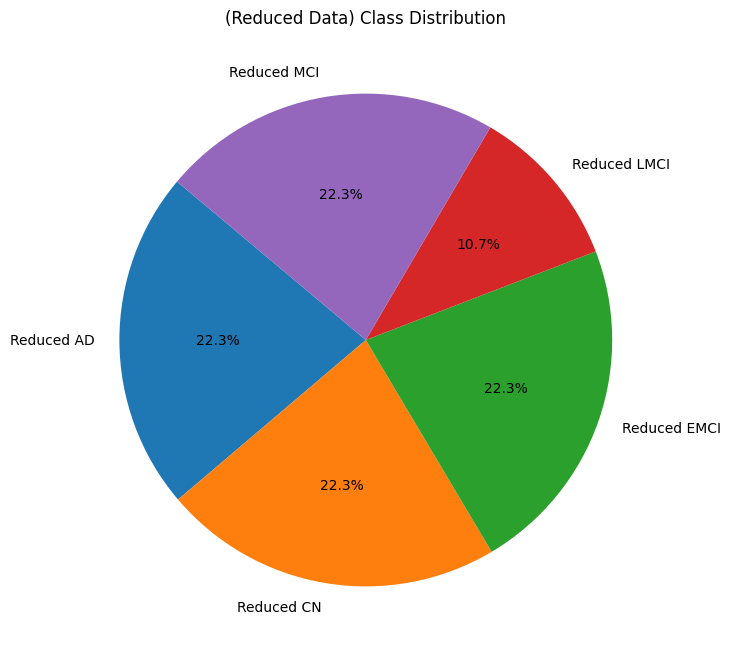

In [233]:
from collections import Counter

# Calculate class distribution
class_counts = Counter(Ytrain)
total_samples = len(Ytrain)

# Baseline accuracy is the proportion of the largest class
baseline_accuracy = max(class_counts.values()) / total_samples
print(f"Baseline Accuracy: {baseline_accuracy:.2%}")

# Generate a pie chart for class distribution
labels = class_counts.keys()
sizes = class_counts.values()

plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140)
plt.title('(Reduced Data) Class Distribution')
plt.show()

Image example: Reduced CN


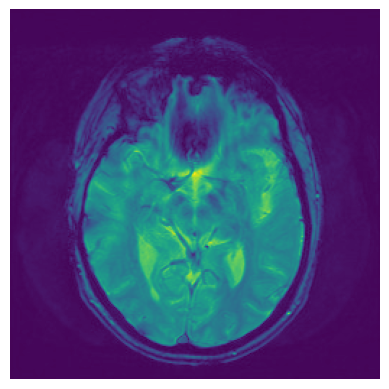

Image dimensions: (256, 256)
Number of channels: 3


In [243]:
# Get random image from Reduced AD
labels = os.listdir(train_path)
random_label = np.random.choice(labels)
random_img = np.random.choice((os.listdir(os.path.join(train_path, random_label))))
img_path = os.path.join(train_path, random_label, random_img)
img = plt.imread(img_path)

# Display the above image
print("Image example:", random_label)
plt.imshow(img)
plt.axis('off')
plt.show()

# Image info
print("Image dimensions:", img.shape[0:2])
print("Number of channels:", "3")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


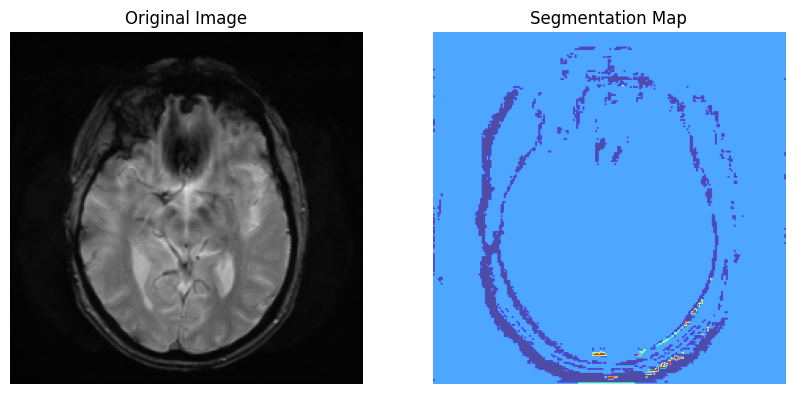

In [273]:
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate
from tensorflow.keras.preprocessing.image import img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Define a UNet-like architecture
def build_unet(input_shape=(224, 224, 3)):
    inputs = Input(input_shape)
    c1 = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = Conv2D(128, (3, 3), activation='relu', padding='same')(p1)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = Conv2D(256, (3, 3), activation='relu', padding='same')(p2)

    u1 = UpSampling2D((2, 2))(c3)
    m1 = concatenate([u1, c2])
    c4 = Conv2D(128, (3, 3), activation='relu', padding='same')(m1)

    u2 = UpSampling2D((2, 2))(c4)
    m2 = concatenate([u2, c1])
    c5 = Conv2D(64, (3, 3), activation='relu', padding='same')(m2)

    outputs = Conv2D(5, (1, 1), activation='softmax')(c5)
    return Model(inputs, outputs)

# Build UNet and compile
unet_model = build_unet()
unet_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Resize and preprocess the image
resized_img = cv2.resize(img, (224, 224))

# If the image has only one channel, convert it to 3 channels
if len(resized_img.shape) == 2 or resized_img.shape[-1] == 1:
    resized_img = cv2.cvtColor(resized_img, cv2.COLOR_GRAY2RGB)

input_img = img_to_array(resized_img) / 255.0
input_img = np.expand_dims(input_img, axis=0)

# Predict segmentation
segmentation_map = unet_model.predict(input_img)

# Visualize
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(resized_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Segmentation Map")
plt.imshow(np.argmax(segmentation_map.squeeze(), axis=-1), cmap='jet', alpha=0.7)
plt.axis('off')
plt.show()



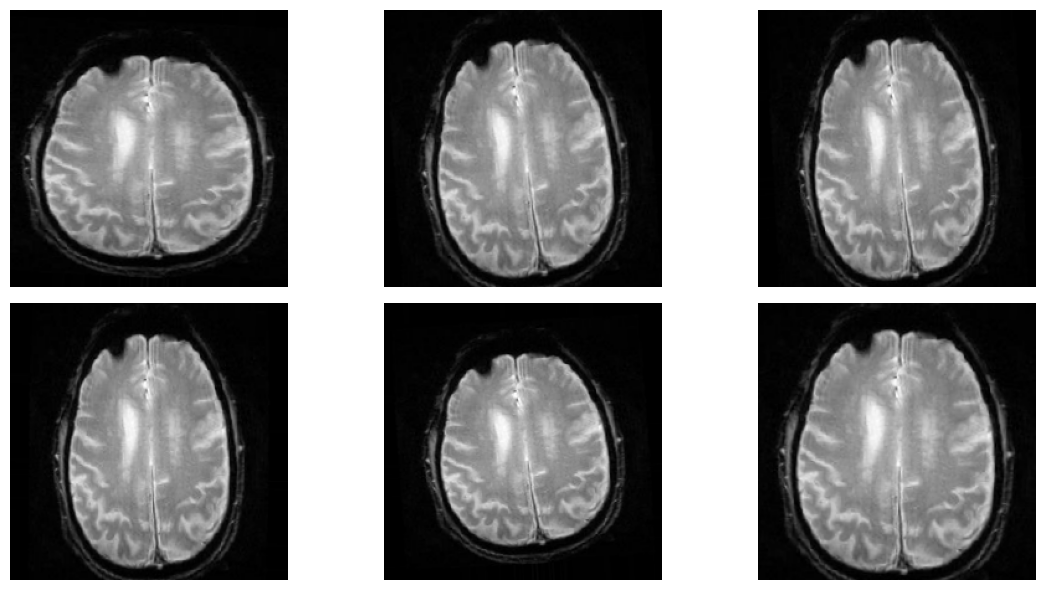

In [274]:
# Get random image from Reduced AD
labels = os.listdir(train_path)
random_label = np.random.choice(labels)
random_img = np.random.choice((os.listdir(os.path.join(train_path, random_label))))
img_path = os.path.join(train_path, random_label, random_img)

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, array_to_img, load_img

# Load a sample image
sample_img_path = img_path  # Replace with the path to an example image
sample_img = load_img(sample_img_path, target_size=(224, 224))  # Resize image to target size
sample_img_array = img_to_array(sample_img)  # Convert image to array
sample_img_array = np.expand_dims(sample_img_array, axis=0)  # Add batch dimension

# Create the ImageDataGenerator with the same settings as in your code
train_datagen = ImageDataGenerator(
    preprocessing_function=None,  # Replace with preprocess_input if needed
    shear_range=0.15,
    zoom_range=0.15,
    rotation_range=5,
    fill_mode='nearest',
    validation_split=0.2  # This won't affect augmentation display
)

# Generate augmented images
augmented_images = train_datagen.flow(sample_img_array, batch_size=1)

# Plot the augmented images
plt.figure(figsize=(12, 6))
for i in range(6):  # Display 6 augmented versions of the image
    augmented_img = next(augmented_images)[0].astype('uint8')  # Get the next augmented image
    plt.subplot(2, 3, i + 1)
    plt.imshow(array_to_img(augmented_img))
    plt.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
# Number of samples
print("Number of samples by class:")
for label in sorted(labels):
  print(f"- {label}: {len(os.listdir(os.path.join(train_path, label)))}")

Number of samples by class:
- Reduced AD: 150
- Reduced CN: 150
- Reduced EMCI: 150
- Reduced LMCI: 72
- Reduced MCI: 150


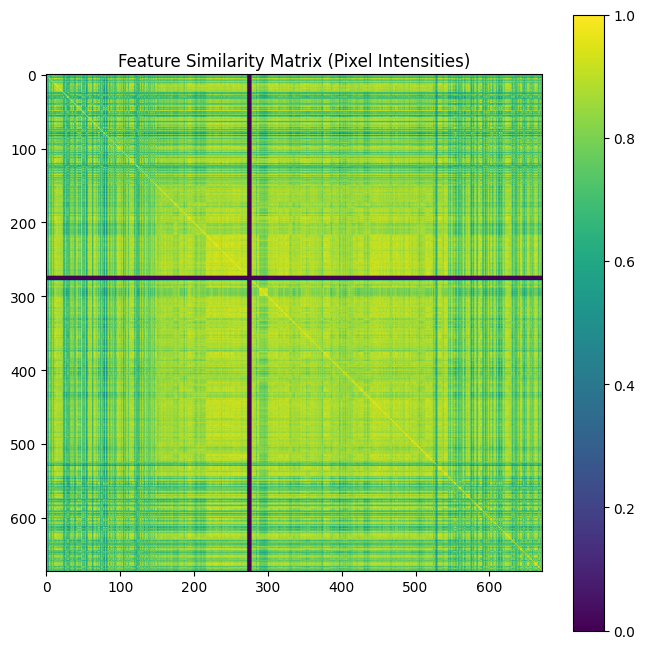

C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


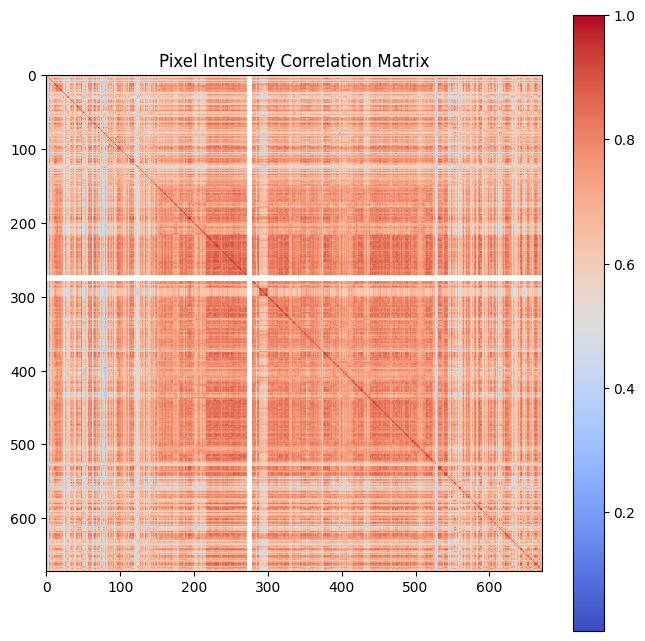

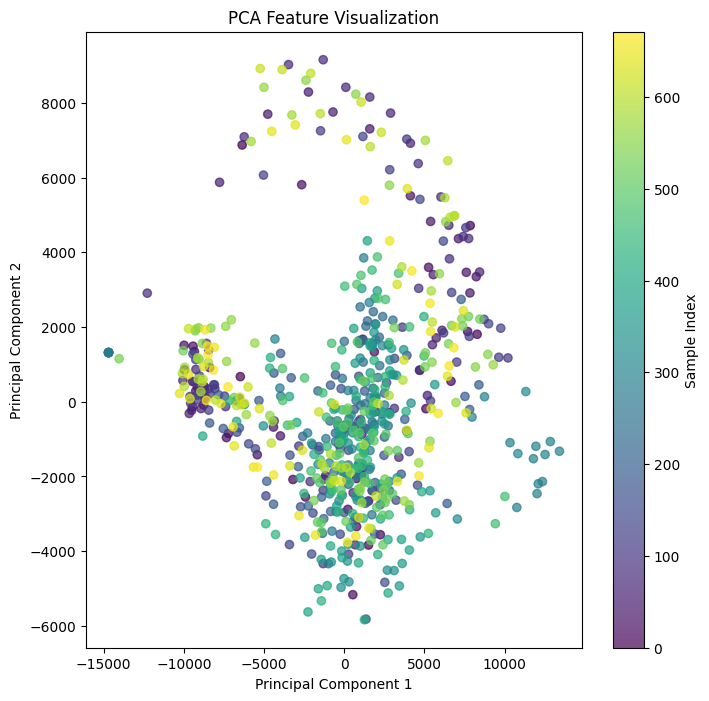

Structural Similarity Index (SSI) between the first two images: 0.2994


In [241]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from skimage.metrics import structural_similarity as ssim

# Feature Similarity Matrix
flattened_features = Xtrain.reshape(Xtrain.shape[0], -1)
similarity_matrix = cosine_similarity(flattened_features)

plt.figure(figsize=(8, 8))
plt.imshow(similarity_matrix, cmap='viridis')
plt.colorbar()
plt.title("Feature Similarity Matrix (Pixel Intensities)")
plt.show()

# Pixel Intensity Correlation Matrix
correlation_matrix = np.corrcoef(flattened_features)

plt.figure(figsize=(8, 8))
plt.imshow(correlation_matrix, cmap='coolwarm')
plt.colorbar()
plt.title("Pixel Intensity Correlation Matrix")
plt.show()

# PCA for Feature Visualization
pca = PCA(n_components=2)
reduced_features = pca.fit_transform(flattened_features)

plt.figure(figsize=(8, 8))
plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=np.arange(len(reduced_features)), cmap='viridis', alpha=0.7)
plt.colorbar(label="Sample Index")
plt.title("PCA Feature Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# Structural Similarity Index (SSI)
# Compute SSI between the first two images
if Xtrain.shape[0] > 1:
    image1 = Xtrain[0].astype('uint8')  # Convert to uint8 for SSIM
    image2 = Xtrain[1].astype('uint8')

    # Convert to grayscale
    image1_gray = cv2.cvtColor(image1, cv2.COLOR_RGB2GRAY)
    image2_gray = cv2.cvtColor(image2, cv2.COLOR_RGB2GRAY)

    ssi_score, _ = ssim(image1_gray, image2_gray, full=True)
    print(f"Structural Similarity Index (SSI) between the first two images: {ssi_score:.4f}")



---
##### Data Curation:
---

In [213]:
# code...

---
##### Data Augmentation / Feature Engineering:
---

In [214]:
# code...

---
##### Final Data Visualization:
---

In [215]:
# code...

---
##### Define Model:
---

In [216]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Flatten, TimeDistributed, LSTM
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import models
from tensorflow.keras import regularizers
from tensorflow.keras import layers
import numpy as np

# Encode labels to integers
label_encoder = LabelEncoder()
Ytrain_encoded = label_encoder.fit_transform(Ytrain)
Ytest_encoded = label_encoder.transform(Ytest)

# Convert labels to one-hot encoding
Ytrain_onehot = to_categorical(Ytrain_encoded)
Ytest_onehot = to_categorical(Ytest_encoded)

# Reshape image data to treat each row as a sequence
# Assuming images are already normalized
Xtrain_rnn = Xtrain.reshape(Xtrain.shape[0], image_size, image_size * 3)  # Flatten columns in each row
Xtest_rnn = Xtest.reshape(Xtest.shape[0], image_size, image_size * 3)


In [234]:
# Base model, TBD
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(256, 256, 3))

# L2 regularizer
l2_reg = regularizers.l2(0.0001)

# Build the improved model
model = models.Sequential()
model.add(base_model)
model.add(layers.GlobalAveragePooling2D())  # Replaces Flatten for better efficiency

# Add dense layers with L2 regularization and batch normalization
model.add(layers.Dense(1024, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.4))  # Adjusted Dropout

model.add(layers.Dense(512, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.4))  # Adjusted Dropout

model.add(layers.Dense(256, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

model.add(layers.Dense(128, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

model.add(layers.Dense(64, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

# Output layer
model.add(layers.Dense(5, activation='softmax'))  # Output layer for 5 classes

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,391,429 (100.68 MB)

 Trainable params: 26,334,341 (100.46 MB)

 Non-trainable params: 57,088 (223.00 KB)

In [235]:
from tensorflow.keras.applications.vgg19 import VGG19
vgg = VGG19(weights='imagenet',
            include_top = False,input_shape=(256, 256, 3)
           )
for layer in vgg.layers:
    layer.trainable = False
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten,Dense
model3 = Sequential()
model3.add(vgg)
model3.add(Flatten())
model3.add(Dense(5,activation="softmax"))

# Compile and run the model
model3.compile(optimizer='Adam',loss='categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,391,429 (100.68 MB)

 Trainable params: 26,334,341 (100.46 MB)

 Non-trainable params: 57,088 (223.00 KB)

In [236]:
# RNN Model
modelRNN = Sequential()
# Add LSTM layers with Dropout for regularization
modelRNN.add(LSTM(128, input_shape=(image_size, image_size * 3), return_sequences=True, dropout=0.3, recurrent_dropout=0.2))
modelRNN.add(LSTM(64, return_sequences=False, dropout=0.3, recurrent_dropout=0.2))
# Add fully connected (Dense) layers with Dropout
modelRNN.add(Dense(32, activation='relu'))
modelRNN.add(Dropout(0.4))  # Dropout on the dense layer
# Output layer
modelRNN.add(Dense(len(labels), activation='softmax'))

modelRNN.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,391,429 (100.68 MB)

 Trainable params: 26,334,341 (100.46 MB)

 Non-trainable params: 57,088 (223.00 KB)

In [237]:
from tensorflow.keras.layers import Bidirectional

# BiLSTM Model
modelBiLSTM = Sequential()
# Add Bidirectional LSTM layers with Dropout
modelBiLSTM.add(Bidirectional(LSTM(128, return_sequences=True, dropout=0.3, recurrent_dropout=0.2), 
                               input_shape=(image_size, image_size * 3)))
modelBiLSTM.add(Bidirectional(LSTM(64, return_sequences=False, dropout=0.3, recurrent_dropout=0.2)))
# Add fully connected (Dense) layers with Dropout
modelBiLSTM.add(Dense(32, activation='relu'))
modelBiLSTM.add(Dropout(0.4))  # Dropout on the dense layer
# Output layer
modelBiLSTM.add(Dense(len(labels), activation='softmax'))

# Compile the model
modelBiLSTM.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,391,429 (100.68 MB)

 Trainable params: 26,334,341 (100.46 MB)

 Non-trainable params: 57,088 (223.00 KB)

---
##### Model Training:
---

In [220]:
from tensorflow.keras.backend import clear_session

clear_session()  # Clear the backend session

# Train the model
history = modelBiLSTM.fit(
    Xtrain_rnn, Ytrain_onehot,
    validation_data=(Xtest_rnn, Ytest_onehot),
    epochs=25,
    batch_size=32
)

# Evaluate the model
test_loss, test_accuracy = modelBiLSTM.evaluate(Xtest_rnn, Ytest_onehot)
print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy}")

Epoch 1/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 17s 503ms/step - accuracy: 0.2475 - loss: 1.5825 - val_accuracy: 0.2143 - val_loss: 1.6524
Epoch 2/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 425ms/step - accuracy: 0.2835 - loss: 1.5605 - val_accuracy: 0.2574 - val_loss: 1.6471
Epoch 3/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 454ms/step - accuracy: 0.3430 - loss: 1.5060 - val_accuracy: 0.2411 - val_loss: 1.6698
Epoch 4/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 429ms/step - accuracy: 0.3309 - loss: 1.4760 - val_accuracy: 0.2470 - val_loss: 1.7014
Epoch 5/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 432ms/step - accuracy: 0.3354 - loss: 1.4285 - val_accuracy: 0.2485 - val_loss: 1.7491
Epoch 6/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 439ms/step - accuracy: 0.3615 - loss: 1.4265 - val_accuracy: 0.2530 - val_loss: 1.7624
Epoch 7/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 440ms/step - accuracy: 0.3819 - loss: 1.3895 - val_accuracy: 0.2530 - val_loss: 1.7673
Epoch 8/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 421ms/step - accuracy: 0.4416 - loss: 1.3328 - val_accuracy: 0

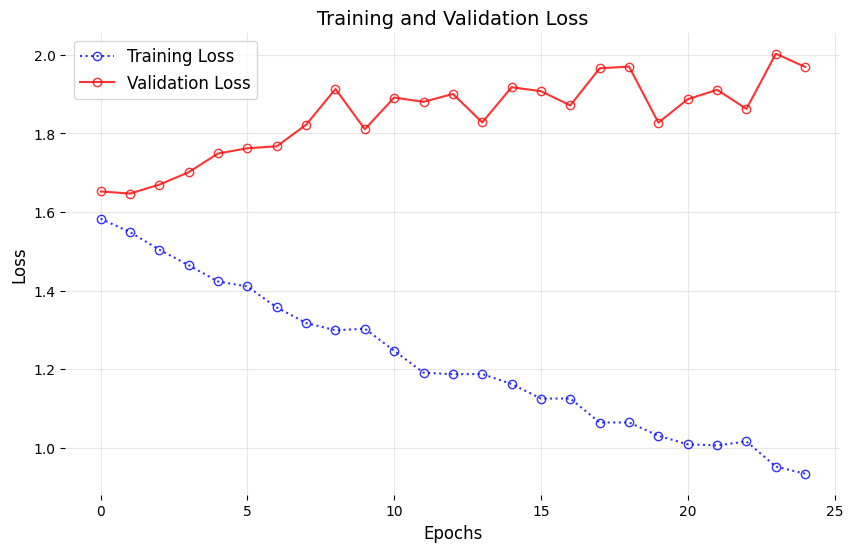

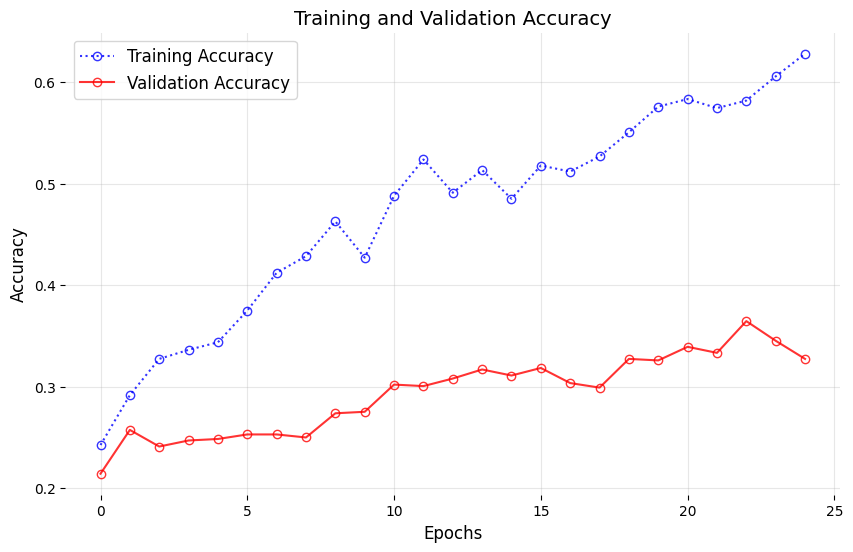

In [224]:

# Plot Training and Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(
    history.history['loss'],
    linestyle='dotted',
    color='blue',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Training Loss'
)
plt.plot(
    history.history['val_loss'],
    linestyle='solid',
    color='red',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Validation Loss'
)
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)

# Remove axes lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

# Add grid for reference
plt.grid(alpha=0.3)
plt.show()

# Plot Training and Validation Accuracy
plt.figure(figsize=(10, 6))
plt.plot(
    history.history['accuracy'],
    linestyle='dotted',
    color='blue',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Training Accuracy'
)
plt.plot(
    history.history['val_accuracy'],
    linestyle='solid',
    color='red',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Validation Accuracy'
)
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)

# Remove axes lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

# Add grid for reference
plt.grid(alpha=0.3)
plt.show()

---
##### Model Testing:
---

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step


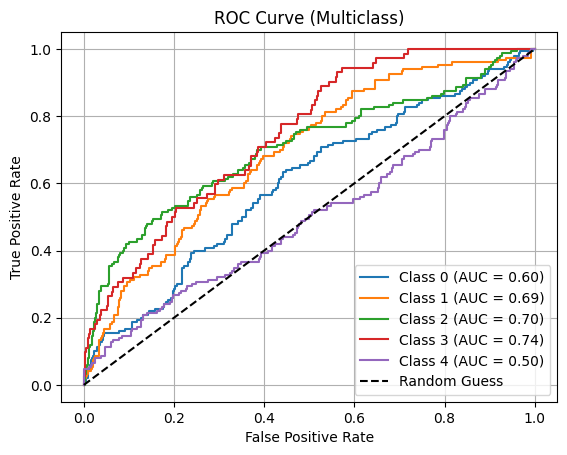

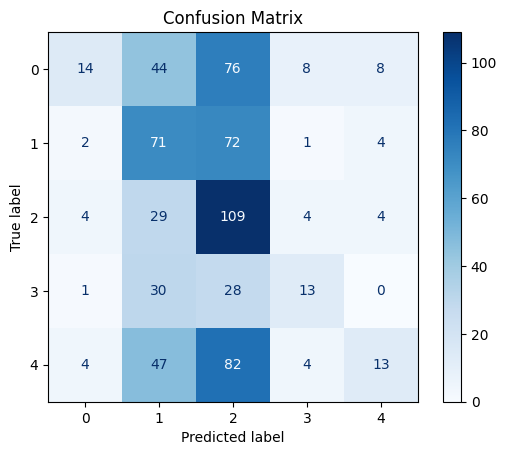

Confusion Matrix:
[[ 14  44  76   8   8]
 [  2  71  72   1   4]
 [  4  29 109   4   4]
 [  1  30  28  13   0]
 [  4  47  82   4  13]]


In [225]:
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Get predictions
Ypred_probs = modelBiLSTM.predict(Xtest_rnn)  # Predicted probabilities
Ypred_classes = np.argmax(Ypred_probs, axis=1)  # Predicted classes
Ytrue_classes = np.argmax(Ytest_onehot, axis=1)  # True classes

# Plot ROC Curve
if Ytest_onehot.shape[1] == 2:  # Binary classification
    fpr, tpr, _ = roc_curve(Ytrue_classes, Ypred_probs[:, 1])  # Use probabilities for the positive class
    auc_score = roc_auc_score(Ytrue_classes, Ypred_probs[:, 1])

    plt.figure()
    plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.2f})")
    plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid()
    plt.show()
else:  # Multiclass classification (macro-average AUC)
    # Compute ROC curve and AUC for each class
    for i in range(Ytest_onehot.shape[1]):
        fpr, tpr, _ = roc_curve(Ytest_onehot[:, i], Ypred_probs[:, i])
        auc_score = roc_auc_score(Ytest_onehot[:, i], Ypred_probs[:, i])
        plt.plot(fpr, tpr, label=f"Class {i} (AUC = {auc_score:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve (Multiclass)")
    plt.legend()
    plt.grid()
    plt.show()

# Confusion Matrix
conf_matrix = confusion_matrix(Ytrue_classes, Ypred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=np.unique(Ytrue_classes))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

# Print Metrics
print("Confusion Matrix:")
print(conf_matrix)


---
##### Final Results:
---

In [223]:
# code...

---
##### Supplementary:
---

In [ ]:
# UNUSED CNN CODE:
'''
cwd = os.getcwd()
train_path = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "train")
test_path = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "test")

train_datagen = ImageDataGenerator(
    validation_split=0.2  # 20% validation split
)

# Create train_generator iterator object
train_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='training',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Create train_generator iterator object
val_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='validation',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Test data generator
test_datagen = ImageDataGenerator(rescale=1./255)  # Only rescaling, no augmentation

# Test generator
test_generator = test_datagen.flow_from_directory(
    test_path, 
    target_size=(256, 256),
    color_mode='rgb',
    batch_size=16,
    seed=1,
    class_mode='categorical',
    shuffle=False  # Do not shuffle to keep predictions in order
)

# Base model, TBD
from tensorflow.keras.applications import MobileNet


base_model=MobileNet(weights='imagenet',
                     include_top=False, 
                     input_shape=(256,256,3))  # shape of RGB images

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(256, 256, 3))


# Modification of Base model
from tensorflow.keras import models
from tensorflow.keras import regularizers
from tensorflow.keras import layers

# L2 regularizer
l2_reg = regularizers.l2(0.0001)

# Build the improved model
model = models.Sequential()
model.add(base_model)
model.add(layers.GlobalAveragePooling2D())  # Replaces Flatten for better efficiency

# Add dense layers with L2 regularization and batch normalization
model.add(layers.Dense(1024, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.4))  # Adjusted Dropout

model.add(layers.Dense(512, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.4))  # Adjusted Dropout

model.add(layers.Dense(256, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

model.add(layers.Dense(128, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

model.add(layers.Dense(64, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

# Output layer
model.add(layers.Dense(5, activation='softmax'))  # Output layer for 5 classes

from tensorflow.keras.applications.vgg19 import VGG19
vgg = VGG19(weights='imagenet',
            include_top = False,input_shape=(256, 256, 3)
           )
for layer in vgg.layers:
    layer.trainable = False
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten,Dense
model3 = Sequential()
model3.add(vgg)
model3.add(Flatten())
model3.add(Dense(5,activation="softmax"))

# Compile and run the model
model3.compile(optimizer='Adam',loss='categorical_crossentropy',metrics=['accuracy'])

# Calculate step sizes
import math
step_size_train = math.ceil(train_generator.n / train_generator.batch_size) 
step_size_val = math.ceil(val_generator.n / val_generator.batch_size) 

# Reset generators at the beginning of each epoch
train_generator.reset()
val_generator.reset()

history = model3.fit(
    train_generator,
    steps_per_epoch=step_size_train,
    epochs=10,
    validation_data=val_generator,
    validation_steps=step_size_val
)

# Plot Training and Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(
    history.history['loss'],
    linestyle='dotted',
    color='blue',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Training Loss'
)
plt.plot(
    history.history['val_loss'],
    linestyle='solid',
    color='red',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Validation Loss'
)
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)

# Remove axes lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

# Add grid for reference
plt.grid(alpha=0.3)
plt.show()

# Plot Training and Validation Accuracy
plt.figure(figsize=(10, 6))
plt.plot(
    history.history['accuracy'],
    linestyle='dotted',
    color='blue',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Training Accuracy'
)
plt.plot(
    history.history['val_accuracy'],
    linestyle='solid',
    color='red',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Validation Accuracy'
)
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)

# Remove axes lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

# Add grid for reference
plt.grid(alpha=0.3)
plt.show()

from sklearn.metrics import roc_curve, auc

# Get true labels and predicted probabilities
y_true = train_generator.classes  # True class labels
y_pred = model.predict(train_generator)  # Predicted probabilities for each class

# One-hot encode the true labels
from tensorflow.keras.utils import to_categorical
y_true_one_hot = to_categorical(y_true, num_classes=5)

# Plotting ROC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i in range(5):  # Assuming 5 classes
    fpr[i], tpr[i], _ = roc_curve(y_true_one_hot[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(10, 8))
for i in range(5):
    plt.plot(fpr[i], tpr[i], label=f'Class {i+1} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Each Class')
plt.legend(loc="lower right")
plt.show()

# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(test_generator, steps=test_generator.n // test_generator.batch_size + 1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

from sklearn.metrics import roc_curve, auc

# Get the true labels
true_classes = test_generator.classes  # True class labels from the test generator
class_labels = list(test_generator.class_indices.keys())  # Class names

# One-hot encode the true labels (if needed)
true_classes = to_categorical(true_classes, num_classes=len(class_labels))

# Predict probabilities for the test set
predictions = model.predict(test_generator)

# Plotting ROC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i in range(5):  # Assuming 5 classes
    fpr[i], tpr[i], _ = roc_curve(true_classes[:, i], predictions[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(10, 8))
for i in range(5):
    plt.plot(fpr[i], tpr[i], label=f'Class {i+1} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Each Class')
plt.legend(loc="lower right")
plt.show()

# Predict class probabilities
predictions = model.predict(test_generator)

# Convert probabilities to class labels
predicted_classes = predictions.argmax(axis=1)

# True class labels
true_classes = test_generator.classes

# Class labels
class_labels = list(test_generator.class_indices.keys())

# Display a classification report
from sklearn.metrics import classification_report

print(classification_report(true_classes, predicted_classes, target_names=class_labels))

from sklearn.metrics import confusion_matrix
import seaborn as sns

# Confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()
'''